# 02b · Overfitting or underfitting? (Figure 5)

Notebook 02 shows that the test accuracy of the polynomial models depends strongly on the inputs and on $C$.  Test
accuracy alone, however, cannot tell us *how* a model fails: a model that memorises its training data and a model
that is too constrained to fit it can end up with the same test score.  Comparing training with test accuracy
separates the two.  The Bayes level $1-\eta\approx96.1\%$ is a convenient yardstick here: no classifier can be right
on more than about 96% of fresh labels, so a model that fits more of its *training* labels than that is fitting
label noise.

We ask two questions.  First, does choosing $C$ on validation data, as we do in notebook 02, make our sparse model
overfit?  Second, are the mock paper's low accuracies a case of overfitting or of underfitting?  Both parts reuse the
selected coordinates and the chosen values of $C$ from notebook 02 (`poly_sparse.json`), so that notebook has to be
run first.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression

from krypto.data import load, split, mock_split, NS, SEEDS
from krypto.polynomial import parity_features, agreements, polyfeatures_kernel_table, kernel_logreg
from krypto.stats import mean_ci, save_json, load_json
from krypto.energy import track
from krypto.plotting import use_paper_style, save, FULL, COLORS, pct

print("plot backend:", use_paper_style())
warnings.filterwarnings("ignore", category=ConvergenceWarning)    # the largest C values converge slowly
sparse = load_json("poly_sparse.json")                             # selected sets and chosen C (notebook 02)
lim = load_json("poly_limit.json")                                 # eta and the infinite-data limit (notebook 02)
eta = lim["eta"]
print(f"label-noise rate eta = {eta:.4f}, Bayes level {100 * (1 - eta):.1f}%")

plot backend: usetex
label-noise rate eta = 0.0391, Bayes level 96.1%


## 1. Does choosing $C$ on validation data overfit?
For each $n$, split and degree $d\in\{6,10\}$ we refit the sparse model on the 10 selected bits for a grid of $C$
that runs from below the mock paper's 0.85 to an essentially unregularised $10^6$, and record the accuracy on all
three parts of the split.  If tuning $C$ led to overfitting, training accuracy would climb above the Bayes level at
large $C$ while test accuracy falls.  We go through the values of $C$ in increasing order and warm-start each fit
from the previous one, which keeps the sweep fast.

We also count how many training points fall into each of the $2^{10}$ cells of the selected bits.  With on average
7–19 points per cell there is enough data to estimate even a degree-10 model on these bits.

In [2]:
DEGREES = (6, 10)
C_VALUES = [0.1, 0.85, 3, 10, 30, 100, 300, 1000, 3000, 10000, 1e5, 1e6]
C_GRID = [0.85, 10, 100, 1000, 10000]          # the candidates of notebook 02
PARTS = ("train", "val", "test")

acc = {str(n): {str(d): {p: [] for p in PARTS} for d in DEGREES} for n in NS}
cells = {}
for n in NS:
    X, y = load(f"kryptonite-{n}")
    with track(f"02_overfit_n{n}"):
        for seed in SEEDS:
            X_tr, y_tr, X_va, y_va, X_te, y_te = split(X, y, seed)
            S = sparse[str(n)]["S"][seed]
            if seed == 0:
                count = np.bincount((X_tr[:, S] < 0).astype(int) @ (1 << np.arange(len(S))), minlength=1 << len(S))
                cells[str(n)] = {"train": len(y_tr), "empty": int((count == 0).sum()), "median": float(np.median(count))}
            for d in DEGREES:
                F = [parity_features(Z, S, d) for Z in (X_tr, X_va, X_te)]
                lr = LogisticRegression(fit_intercept=False, max_iter=5000, tol=1e-8, warm_start=True)
                rows = []
                for C in C_VALUES:                       # increasing C, warm-started from the previous fit
                    lr.set_params(C=C).fit(F[0], y_tr)
                    rows.append([lr.score(f, t) for f, t in zip(F, (y_tr, y_va, y_te))])
                for p, column in zip(PARTS, np.array(rows).T):
                    acc[str(n)][str(d)][p].append(column.tolist())
    print(f"n={n} done", flush=True)
save_json({"C": C_VALUES, "accuracy": acc, "cells_seed0": cells}, "poly_overfit.json")

[track] 02_overfit_n20: 33.7 s
n=20 done


[track] 02_overfit_n30: 54.4 s
n=30 done


[track] 02_overfit_n40: 138.5 s
n=40 done


In [3]:
for n in NS:
    c = cells[str(n)]
    print(f"n={n}: {c['train']} training points, {c['empty']} empty cells of 1024, median {c['median']:.0f} per cell")
    for d in DEGREES:
        a = {p: np.array(acc[str(n)][str(d)][p]) for p in PARTS}     # seeds x C
        gap = (a["train"] - a["test"]).mean(0)
        hi = [i for i, C in enumerate(C_VALUES) if C >= 1000]
        print(f"   d={d:2d}: train-test gap at C=0.85 {100 * gap[C_VALUES.index(0.85)]:+.1f} pts, "
              f"largest gap for C>=1000 {100 * gap[hi].max():+.1f} pts, "
              f"highest train accuracy {100 * a['train'].max():.1f}% (Bayes {100 * (1 - eta):.1f}%)")

n=20: 7200 training points, 1 empty cells of 1024, median 7 per cell
   d= 6: train-test gap at C=0.85 +4.3 pts, largest gap for C>=1000 +1.1 pts, highest train accuracy 96.0% (Bayes 96.1%)
   d=10: train-test gap at C=0.85 +4.5 pts, largest gap for C>=1000 +0.4 pts, highest train accuracy 96.0% (Bayes 96.1%)
n=30: 12000 training points, 0 empty cells of 1024, median 11 per cell
   d= 6: train-test gap at C=0.85 +3.6 pts, largest gap for C>=1000 +0.3 pts, highest train accuracy 96.2% (Bayes 96.1%)
   d=10: train-test gap at C=0.85 +2.7 pts, largest gap for C>=1000 +0.1 pts, highest train accuracy 96.2% (Bayes 96.1%)
n=40: 19200 training points, 0 empty cells of 1024, median 19 per cell
   d= 6: train-test gap at C=0.85 +2.1 pts, largest gap for C>=1000 +0.3 pts, highest train accuracy 96.2% (Bayes 96.1%)
   d=10: train-test gap at C=0.85 +1.5 pts, largest gap for C>=1000 +0.2 pts, highest train accuracy 96.2% (Bayes 96.1%)


### Supplementary figure
Train, validation and test accuracy against $C$ (mean and 95% interval over the 5 splits).  The shaded band is the
grid notebook 02 chooses from, and the dash-dotted line marks the median of the chosen values.

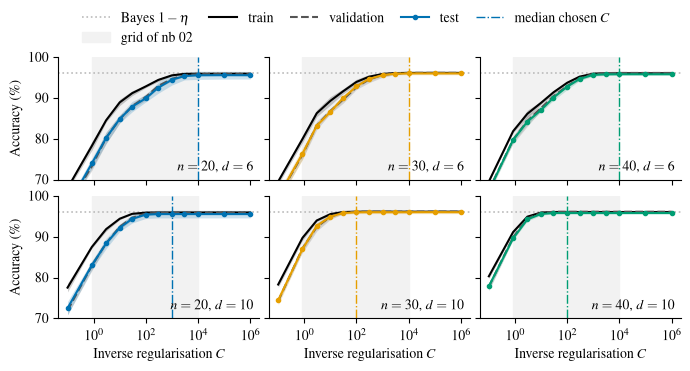

In [4]:
Cs = np.array(C_VALUES)
fig, axes = plt.subplots(len(DEGREES), len(NS), figsize=(FULL, 3.6), sharex=True, sharey=True)
styles = {"train": dict(color="k", ls="-", label="train"),
          "val": dict(color=COLORS["gray"], ls="--", label="validation"),
          "test": dict(ls="-", marker="o", ms=3, label="test")}
for row, d in enumerate(DEGREES):
    for col, n in enumerate(NS):
        ax = axes[row, col]
        a = {p: np.array(acc[str(n)][str(d)][p]) for p in PARTS}
        ax.axhline(100 * (1 - eta), color="#bbbbbb", ls=":", lw=1.2, label=r"Bayes $1-\eta$")
        ax.axvspan(min(C_GRID), max(C_GRID), color="#f2f2f2", zorder=0, label="grid of nb 02")
        for p in PARTS:
            st = np.array([mean_ci(a[p][:, i]) for i in range(len(Cs))]) * 100
            kw = dict(styles[p], color=styles[p].get("color", COLORS[n]))
            ax.plot(Cs, st[:, 0], **kw)
            ax.fill_between(Cs, st[:, 0] - st[:, 1], st[:, 0] + st[:, 1], color=kw["color"], alpha=0.2, lw=0)
        best = [C_GRID[int(np.argmax([v[C_VALUES.index(c)] for c in C_GRID]))] for v in a["val"]]
        ax.axvline(np.median(best), color=COLORS[n], ls="-.", lw=1, label=r"median chosen $C$")
        ax.set_xscale("log")
        ax.set_ylim(70, 100)
        ax.text(0.97, 0.05, f"$n={n}$, $d={d}$", transform=ax.transAxes, ha="right", va="bottom")
        if row == len(DEGREES) - 1:
            ax.set_xlabel("Inverse regularisation $C$")
        if col == 0:
            ax.set_ylabel(pct("Accuracy (%)"))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=5, loc="outside upper center", handlelength=2.0, columnspacing=1.2)
save(fig, "figS_overfit")
plt.show()

**Reading the supplementary figure.** At the mock paper's $C=0.85$ all three accuracies lie well below the Bayes
level: the model is held back by its regulariser.  As $C$ grows, training and test accuracy rise together and level
off at about 96%.  Training accuracy never climbs much above the Bayes level, and the gap to test accuracy stays at
about one point even without regularisation.  Choosing $C$ on validation data therefore does not overfit here, which
is what we would expect from 1,024 features estimated from 7,200–19,200 training points.

## 2. Is the mock paper's failure overfitting or underfitting?
We now compare training and test accuracy against degree for the three models of Figure 2: the mock paper's kernel
model on all $n$ bits (on its own split, $C=0.85$), and the same model on the 10 selected bits with $C=0.85$ or with
the $C$ chosen in notebook 02 (5 splits).  Notebook 02 did not record the mock model's training accuracy, so we refit
it here with the mock paper's code; at $n=40$ each fit again needs about 4 GB of memory.

In [5]:
FIT_DEGREES = list(range(1, 11))
fit = {}
for n in NS:
    X, y = load(f"kryptonite-{n}")
    fit[str(n)] = {"mock": {}, "fixed": {}, "tuned": {}}
    with track(f"02_fit_mock_n{n}"):
        X_tr, y_tr, _, _, X_te, y_te = mock_split(X, y)
        M_tr, M_te = agreements(X_tr, X_tr, n), agreements(X_te, X_tr, n)
        for d in FIT_DEGREES:
            table = polyfeatures_kernel_table(n, d).astype(np.float32)
            K = table[M_tr]                                  # training kernel matrix, N x N
            a = kernel_logreg(K, y_tr, C=0.85)
            fit[str(n)]["mock"][str(d)] = {"train": float(((K @ a > 0) == y_tr).mean()),
                                           "test": float(((table[M_te] @ a > 0) == y_te).mean())}
            del K                                            # free the ~1.5 GB matrix before the next degree
    with track(f"02_fit_sparse_n{n}"):
        for key in ("fixed", "tuned"):
            fit[str(n)][key] = {str(d): {"train": [], "test": []} for d in FIT_DEGREES}
        for seed in SEEDS:
            X_tr, y_tr, _, _, X_te, y_te = split(X, y, seed)
            S = sparse[str(n)]["S"][seed]
            for d in FIT_DEGREES:
                F_tr, F_te = parity_features(X_tr, S, d), parity_features(X_te, S, d)
                for key, C in (("fixed", 0.85), ("tuned", sparse[str(n)]["C"][str(d)][seed])):
                    lr = LogisticRegression(C=C, fit_intercept=False, max_iter=5000, tol=1e-8).fit(F_tr, y_tr)
                    fit[str(n)][key][str(d)]["train"].append(lr.score(F_tr, y_tr))
                    fit[str(n)][key][str(d)]["test"].append(lr.score(F_te, y_te))
    print(f"n={n} done", flush=True)
save_json(fit, "poly_fit_diagnosis.json")

[track] 02_fit_mock_n20: 9.3 s


[track] 02_fit_sparse_n20: 15.9 s
n=20 done


[track] 02_fit_mock_n30: 26.9 s


[track] 02_fit_sparse_n30: 24.3 s
n=30 done


[track] 02_fit_mock_n40: 79.0 s


[track] 02_fit_sparse_n40: 39.2 s
n=40 done


In [6]:
print("accuracy (%) for degrees 1-10")
for n in NS:
    for key, name in (("mock", "all bits, C=0.85"), ("fixed", "10 bits, C=0.85"), ("tuned", "10 bits, tuned C")):
        r = fit[str(n)][key]
        tr = [100 * np.mean(r[str(d)]["train"]) for d in FIT_DEGREES]
        te = [100 * np.mean(r[str(d)]["test"]) for d in FIT_DEGREES]
        print(f"n={n} {name:17s} train " + " ".join(f"{v:5.1f}" for v in tr))
        print(f"{'':23s} test  " + " ".join(f"{v:5.1f}" for v in te))
print(f"Bayes level {100 * (1 - eta):.1f}%")

accuracy (%) for degrees 1-10
n=20 all bits, C=0.85  train  51.9  59.6  70.4  79.1  84.5  89.2  93.4  95.4  97.9  98.8
                        test   50.3  55.3  55.6  57.2  57.0  58.0  57.5  58.1  57.8  58.4
n=20 10 bits, C=0.85   train  52.0  56.9  61.3  69.5  74.9  78.2  81.4  84.3  86.2  87.5
                        test   50.4  55.6  57.3  65.5  69.0  74.0  75.7  79.9  80.7  83.0
n=20 10 bits, tuned C  train  52.0  56.9  61.5  71.7  84.2  95.9  95.9  95.9  95.9  95.9
                        test   50.4  55.6  57.3  67.8  79.2  95.6  95.6  95.6  95.6  95.6
n=30 all bits, C=0.85  train  51.6  59.2  76.8  87.0  95.2  98.4  99.8 100.0 100.0 100.0
                        test   50.5  54.6  53.9  55.2  54.2  55.4  53.6  55.4  54.1  55.4
n=30 10 bits, C=0.85   train  51.6  56.5  59.9  69.6  75.0  79.9  82.8  86.4  88.0  89.7
                        test   51.0  55.9  57.9  66.1  71.1  76.3  79.0  83.1  84.9  87.0
n=30 10 bits, tuned C  train  51.6  56.5  60.1  70.8  81.7  96.2  96.2  96.

## Figure 5
Training accuracy (open markers, thin lines) and test accuracy (filled markers) of each model; the shading between
them is the generalisation gap, and the dotted line is the infinite-data limit from notebook 02.

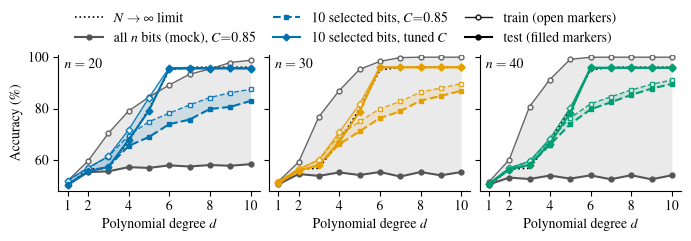

In [7]:
fig, axes = plt.subplots(1, len(NS), figsize=(FULL, 2.3), sharey=True)
d = np.array(FIT_DEGREES)
for ax, n in zip(axes, NS):
    ax.plot(d, [100 * lim["limit"][str(k)] for k in d], color="k", ls=":", lw=1.2, label=r"$N\to\infty$ limit")
    for key, color, ls, mk, lab in (("mock", COLORS["gray"], "-", "o", r"all $n$ bits (mock), $C{=}0.85$"),
                                    ("fixed", COLORS[n], "--", "s", r"10 selected bits, $C{=}0.85$"),
                                    ("tuned", COLORS[n], "-", "D", r"10 selected bits, tuned $C$")):
        r = fit[str(n)][key]
        tr = np.array([100 * np.mean(r[str(k)]["train"]) for k in d])
        te = np.array([100 * np.mean(r[str(k)]["test"]) for k in d])
        ax.fill_between(d, te, tr, color=color, alpha=0.12, lw=0)
        ax.plot(d, tr, color=color, ls=ls, lw=1, marker=mk, ms=3.5, mfc="white", alpha=0.9)
        ax.plot(d, te, color=color, ls=ls, marker=mk, ms=3.5, label=lab)
    ax.set_xlabel("Polynomial degree $d$")
    ax.set_xticks([1, 2, 4, 6, 8, 10]); ax.set_ylim(48, 101)
    ax.text(0.03, 0.97, f"$n={n}$", transform=ax.transAxes, va="top")
axes[0].set_ylabel(pct("Accuracy (%)"))
handles, labels = axes[0].get_legend_handles_labels()
handles += [Line2D([], [], color="k", marker="o", ms=3.5, mfc="white", lw=1, alpha=0.9),   # legend keys for
            Line2D([], [], color="k", marker="o", ms=3.5)]                                 # train vs test
labels += ["train (open markers)", "test (filled markers)"]
fig.legend(handles, labels, ncol=3, loc="outside upper center", handlelength=2.0, columnspacing=1.2)
save(fig, "fig5_fit")
plt.show()

**Reading Figure 5.** The three models fail, or succeed, in three different ways.  On all $n$ bits the mock paper's
model *overfits*: from degree 3 on, its training accuracy climbs steeply, to 98.8–100% at degree 10, above the
Bayes level, so it has memorised label noise; its test accuracy meanwhile stays below 59%.  With
$\binom{n+d}{d}$ features it can fit almost any labelling of the training points, and $C=0.85$ does not prevent
that.  On the 10 selected bits the same $C$ has the opposite effect: from degree 4 on, training and test accuracy
both stay below the infinite-data limit, so the model *underfits*, because the regulariser shrinks the high-degree
parities too strongly.  Once $C$ is chosen on validation data, training and test accuracy agree to within half a
point and reach the limit from degree 6.  A single fixed $C$ cannot suit both feature spaces: the mock paper's low
numbers reflect the dimension of its inputs and an untuned regulariser, not a limit of what polynomials can
represent.